In [37]:
### ESACCI Version Difference ###
import numpy as np
from joblib import load, dump
import rasterio
rng = np.random.default_rng(seed=42)  # 随机数生成器

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
lat, lon = np.arange(-90, 90.1, 1), np.arange(0, 360.1, 1)  # 经纬度网格

import _calGlobal
factor = 1e-7  # 单位换算系数 (MgC/ha -> PgC)
def getGlobal(x, **kwargs):
    return _calGlobal.getGlobalSum(x, factor=factor, **kwargs)

def flipImage(tiff: np.ndarray, shift=180) -> np.ndarray:
    """Flip latitude and shift longitude from original raster layout to 0-360° layout."""
    flipped = np.flip(tiff, axis=0)  # 纬度翻转
    shifted = np.roll(flipped, -shift, axis=1)  # 经度平移
    return shifted


In [38]:
ESA_2010 = load("./Data/ESACCI_2010.joblib")
ESA_2010std = load("./Data/ESACCI-std_2010.joblib")
ESA_2015 = load("./Data/ESACCI_2015.joblib")
ESA_2015std = load("./Data/ESACCI-std_2015.joblib")
ESAv5_mean = np.mean([ESA_2010, ESA_2015], axis=0)  # (lat, lon)
ESAv5_std = np.mean([ESA_2010std, ESA_2015std], axis=0)  # (lat, lon)

ESAv7_data = np.load("./Data/AGBC_ESAv7.npz")
ESAv7_std = np.load("./Data/AGBCsd_ESAv7.npz")
ESAv7_data = {k.title(): flipImage(v) for k, v in ESAv7_data.items()}  # 首字母大写，翻转投影坐标
ESAv7_std = {k.title(): flipImage(v) for k, v in ESAv7_std.items()}
ESAv7_mean = ESAv7_data["Mean"]
print(ESAv7_data.keys())
print(ESAv7_std.keys())

CMIP_set = np.load("./Data/CMIP6_AGBC.npz")
modelNum = len(CMIP_set)  # 模型数量：30
modelNames = list(CMIP_set.keys())

with rasterio.open("./Data/Koppen_2010.tif", "r") as src:
    Koppen = src.read(1).astype(np.float32)
    Koppen = flipImage(Koppen)
#TreeCover:np.ndarray = gdal.Open("./Var/Veg/TreeCover.tif").ReadAsArray()
#TreeCover = flipImage(TreeCover.astype(np.float32))


dict_keys(['2010', '2011', '2012', '2015', 'Mean'])
dict_keys(['2010', '2011', '2012', '2015', 'Mean'])


ESA V5: 286.9 ± 12.0 PgC
ESA V7: 302.8 ± 57.5 PgC
V7/V5: 105.5%,  480.2%


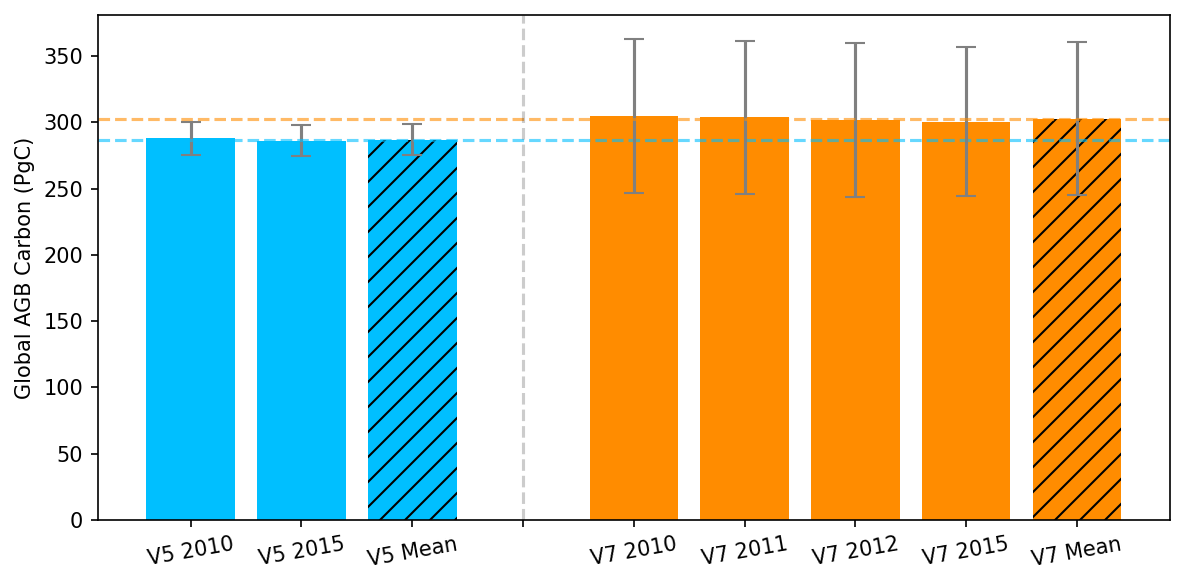

In [39]:
### ----- ESACCI 版本差异 ----- ###

# !!! 未加入 Tree Mask !!!
v5mean, v5std = getGlobal(ESAv5_mean), getGlobal(ESAv5_std)
v7mean, v7std = getGlobal(ESAv7_mean), getGlobal(ESAv7_std["Mean"])
print(f"ESA V5: {v5mean:.1f} ± {v5std:.1f} PgC")
print(f"ESA V7: {v7mean:.1f} ± {v7std:.1f} PgC")
print(f"V7/V5: {v7mean/v5mean*100:.1f}%,  {v7std/v5std*100:.1f}%")

fig, ax = plt.subplots(figsize=(8, 4), dpi=150)

# ESACCI V5
ax.bar(0, getGlobal(ESA_2010), color="deepskyblue")
ax.bar(1, getGlobal(ESA_2015), color="deepskyblue")
ax.bar(2, getGlobal(ESAv5_mean), color="deepskyblue", hatch="//")
ax.errorbar(0, getGlobal(ESA_2010), yerr=getGlobal(ESA_2010std), ecolor="gray", capsize=5)
ax.errorbar(1, getGlobal(ESA_2015), yerr=getGlobal(ESA_2015std), ecolor="gray", capsize=5)
ax.errorbar(2, getGlobal(ESAv5_mean), yerr=getGlobal(ESAv5_std), ecolor="gray", capsize=5)
ax.axhline(v5mean, color="deepskyblue", linestyle="--", alpha=0.6)  # V5 Mean

# ESACCI V7
x = 3
for k in ESAv7_data.keys():
    x += 1
    ax.bar(x, getGlobal(ESAv7_data[k]), color="darkorange", hatch="//" if k == "Mean" else None)
    ax.errorbar(x, getGlobal(ESAv7_data[k]), yerr=getGlobal(ESAv7_std[k]), ecolor="gray", capsize=5)
ax.axhline(v7mean, color="darkorange", linestyle="--", alpha=0.6)  # V7 Mean

ax.axvline(3, color="black", linestyle="--", alpha=0.2)  # 分界线
Label = ["V5 2010", "V5 2015", "V5 Mean", ""] + ["V7 " + k for k in ESAv7_data.keys()]
ax.set_xticks(list(range(x+1)), Label, rotation=10, fontsize=10)
ax.set_ylabel("Global AGB Carbon (PgC)")

plt.tight_layout()
plt.show(fig)


In [40]:
ValidMask = (Koppen > 0) & (ESAv7_mean > 0)  ### Valid Mask
#dump(ValidMask, "./validmask.joblib")
#ValidMask = load("./Data/Masks/validmask.joblib")
TreeMask = load("./Data/Masks/treemask.joblib")  ### Tree Mask

cliDict = {
    "Af": [1],  # 热带雨林
    "Am": [2],  # 热带季风
    "Aw": [3],  # 热带萨瓦纳
    "BW": [4, 5], # 干旱沙漠
    "BS": [6, 7], # 半干旱草原
    "Cs": [8, 9, 10], # 亚热带夏干（地中海）
    "Cw": [11, 12, 13], # 亚热带冬干
    "Cf": [14, 15, 16], # 亚热带全湿
    "Ds": [17, 18, 19, 20], # 寒温带夏干
    "Dw": [21, 22, 23, 24], # 寒温带冬干
    "Df": [25, 26, 27, 28], # 寒温带全湿
    "ET": [29],  # 极地苔原
    "EF": [30]   # 极地冰原
    }

# f=全湿，s=夏干，w=冬干
cliMask = [np.isin(Koppen, ids) for ids in cliDict.values()] ### Climate Mask

ESA V5: 200.7 ± 8.7 PgC
ESA V7: 208.8 ± 38.4 PgC
V7/V5: 104.0%,  440.2%

Zone	Af	Am	Aw	BW	BS	Cs	Cw	Cf	Ds	Dw	Df	ET	EF
V5 Mean	62.3	37.9	31.4	0.0	0.6	1.7	5.8	9.1	1.2	7.1	43.3	0.2	0.0
V7 Mean	67.3	36.7	27.8	0.0	0.5	1.7	8.6	11.7	1.2	6.8	46.2	0.2	0.0
Diff	+5.1	-1.2	-3.6	-0.0	-0.1	+0.1	+2.8	+2.6	+0.0	-0.3	+2.8	-0.0	+0.0
Diff %	+8.2%	-3.2%	-11.4%	-83.7%	-14.6%	+3.4%	+47.7%	+29.0%	+0.1%	-4.5%	+6.5%	-7.8%	--


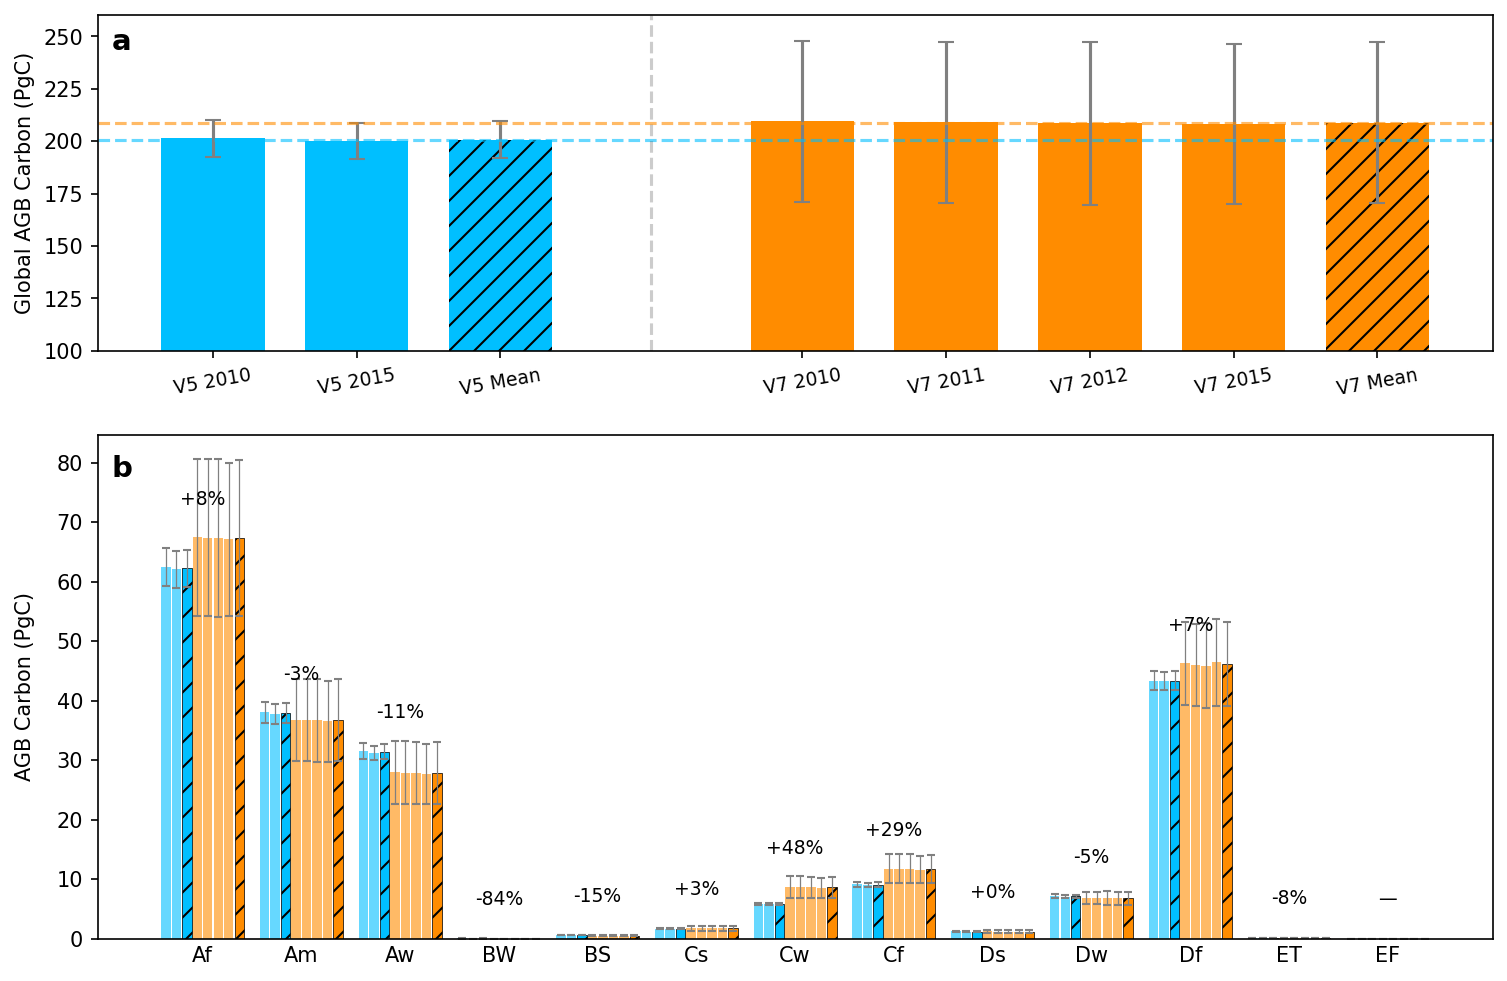

In [41]:
### ----- ESACCI V5/V7 Comparison by Climate Zone ----- ###

# !!! 加入 Tree Mask !!!
v5_series = {
    "2010": (ESA_2010*TreeMask, ESA_2010std*TreeMask),
    "2015": (ESA_2015*TreeMask, ESA_2015std*TreeMask),
    "Mean": (ESAv5_mean*TreeMask, ESAv5_std*TreeMask),
}
v7_series = {
    k: (ESAv7_data[k]*TreeMask, ESAv7_std[k]*TreeMask)
    for k in ESAv7_data.keys()
}

fig, axs = plt.subplots(2, 1, figsize=(12, 8), dpi=150,
    gridspec_kw={"height_ratios": [0.8, 1.2], "hspace": 0.2}
)

### ---------- (a) Global comparison ---------- ###
ax = axs[0]
bar_width = 0.72
x_v5 = np.arange(len(v5_series))
gap = 1.1
x_v7 = np.arange(len(v7_series)) + len(v5_series) + gap

v5_vals = [getGlobal(data) for data, _ in v5_series.values()]
v5_errs = [getGlobal(std) for _, std in v5_series.values()]
v7_vals = [getGlobal(data) for data, _ in v7_series.values()]
v7_errs = [getGlobal(std) for _, std in v7_series.values()]

for x0, label, val, err in zip(x_v5, v5_series.keys(), v5_vals, v5_errs):
    ax.bar(x0, val, width=bar_width, color="deepskyblue", hatch="//" if label == "Mean" else None)
    ax.errorbar(x0, val, yerr=err, ecolor="gray", capsize=4, ls="none")
for x0, label, val, err in zip(x_v7, v7_series.keys(), v7_vals, v7_errs):
    ax.bar(x0, val, width=bar_width, color="darkorange", hatch="//" if label == "Mean" else None)
    ax.errorbar(x0, val, yerr=err, ecolor="gray", capsize=4, ls="none")

v5mean, v5std = getGlobal(v5_series["Mean"][0]), getGlobal(v5_series["Mean"][1])
v7mean, v7std = getGlobal(v7_series["Mean"][0]), getGlobal(v7_series["Mean"][1])
ax.axhline(v5mean, color="deepskyblue", linestyle="--", alpha=0.6)
ax.axhline(v7mean, color="darkorange", linestyle="--", alpha=0.6)
ax.axvline(len(v5_series) - 0.5 + gap/2, color="black", linestyle="--", alpha=0.2)
ax.set_ylim(100, None)

ax.set_xticks(
    list(x_v5) + list(x_v7),
    [f"V5 {k}" for k in v5_series.keys()] + [f"V7 {k}" for k in v7_series.keys()],
    rotation=10, fontsize=9
)
ax.set_ylabel("Global AGB Carbon (PgC)")
ax.text(0.01, 0.96, "a", transform=ax.transAxes, fontsize=14, fontweight="bold", va="top")

print(f"ESA V5: {v5mean:.1f} ± {v5std:.1f} PgC")
print(f"ESA V7: {v7mean:.1f} ± {v7std:.1f} PgC")
print(f"V7/V5: {v7mean/v5mean*100:.1f}%,  {v7std/v5std*100:.1f}%\n")

### ---------- (b) Climate zone comparison ---------- ###
ax = axs[1]
zone_names = list(cliDict.keys())
zone_masks = [TreeMask & mask for mask in cliMask]
series = [("V5", name, data, std) for name, (data, std) in v5_series.items()]
series += [("V7", name, data, std) for name, (data, std) in v7_series.items()]

x = np.arange(len(zone_names))
group_width = 0.85
width = group_width / len(series)
offsets = (np.arange(len(series)) - (len(series) - 1) / 2) * width
colors = {"V5": "deepskyblue", "V7": "darkorange"}

zone_values = {}
for idx, (version, name, data, std) in enumerate(series):
    vals = np.array([getGlobal(data, mask=mask) for mask in zone_masks])
    errs = np.array([getGlobal(std, mask=mask) for mask in zone_masks])
    zone_values[(version, name)] = vals
    ax.bar(
        x + offsets[idx], vals, width=width*0.9, color=colors[version],
        alpha=1. if name == "Mean" else 0.6,
        edgecolor="black" if name == "Mean" else "none",
        linewidth=0.35 if name == "Mean" else 0,
        hatch="//" if name == "Mean" else None,
        label=f"{version} {name}"
    )
    ax.errorbar(x + offsets[idx], vals, yerr=errs, ecolor="gray", capsize=2, ls="none", lw=0.6)

v5_zone_mean = zone_values[("V5", "Mean")]
v7_zone_mean = zone_values[("V7", "Mean")]
for i, (v5, v7) in enumerate(zip(v5_zone_mean, v7_zone_mean)):
    if v5 == 0 or np.isnan(v5):
        label = "—"
    else:
        label = f"{(v7 - v5) / v5 * 100:+.0f}%"
    ax.text(x[i], max(v5, v7) + 5, label, ha="center", va="bottom", fontsize=9)

ax.set_ylabel("AGB Carbon (PgC)")
ax.set_xticks(x, zone_names)
ax.tick_params(axis="x", length=0)
ax.text(0.01, 0.96, "b", transform=ax.transAxes, fontsize=14, fontweight="bold", va="top")

print("\t".join(["Zone"] + zone_names))
print("\t".join(["V5 Mean"] + [f"{v:.1f}" for v in v5_zone_mean]))
print("\t".join(["V7 Mean"] + [f"{v:.1f}" for v in v7_zone_mean]))
print("\t".join(["Diff"] + [f"{v7-v5:+.1f}" for v5, v7 in zip(v5_zone_mean, v7_zone_mean)]))
print("\t".join(["Diff %"] + [f"{(v7-v5)/v5*100:+.1f}%" if v5 != 0 else "--"\
                              for v5, v7 in zip(v5_zone_mean, v7_zone_mean)]))

fig.align_ylabels(axs)
plt.show(fig)


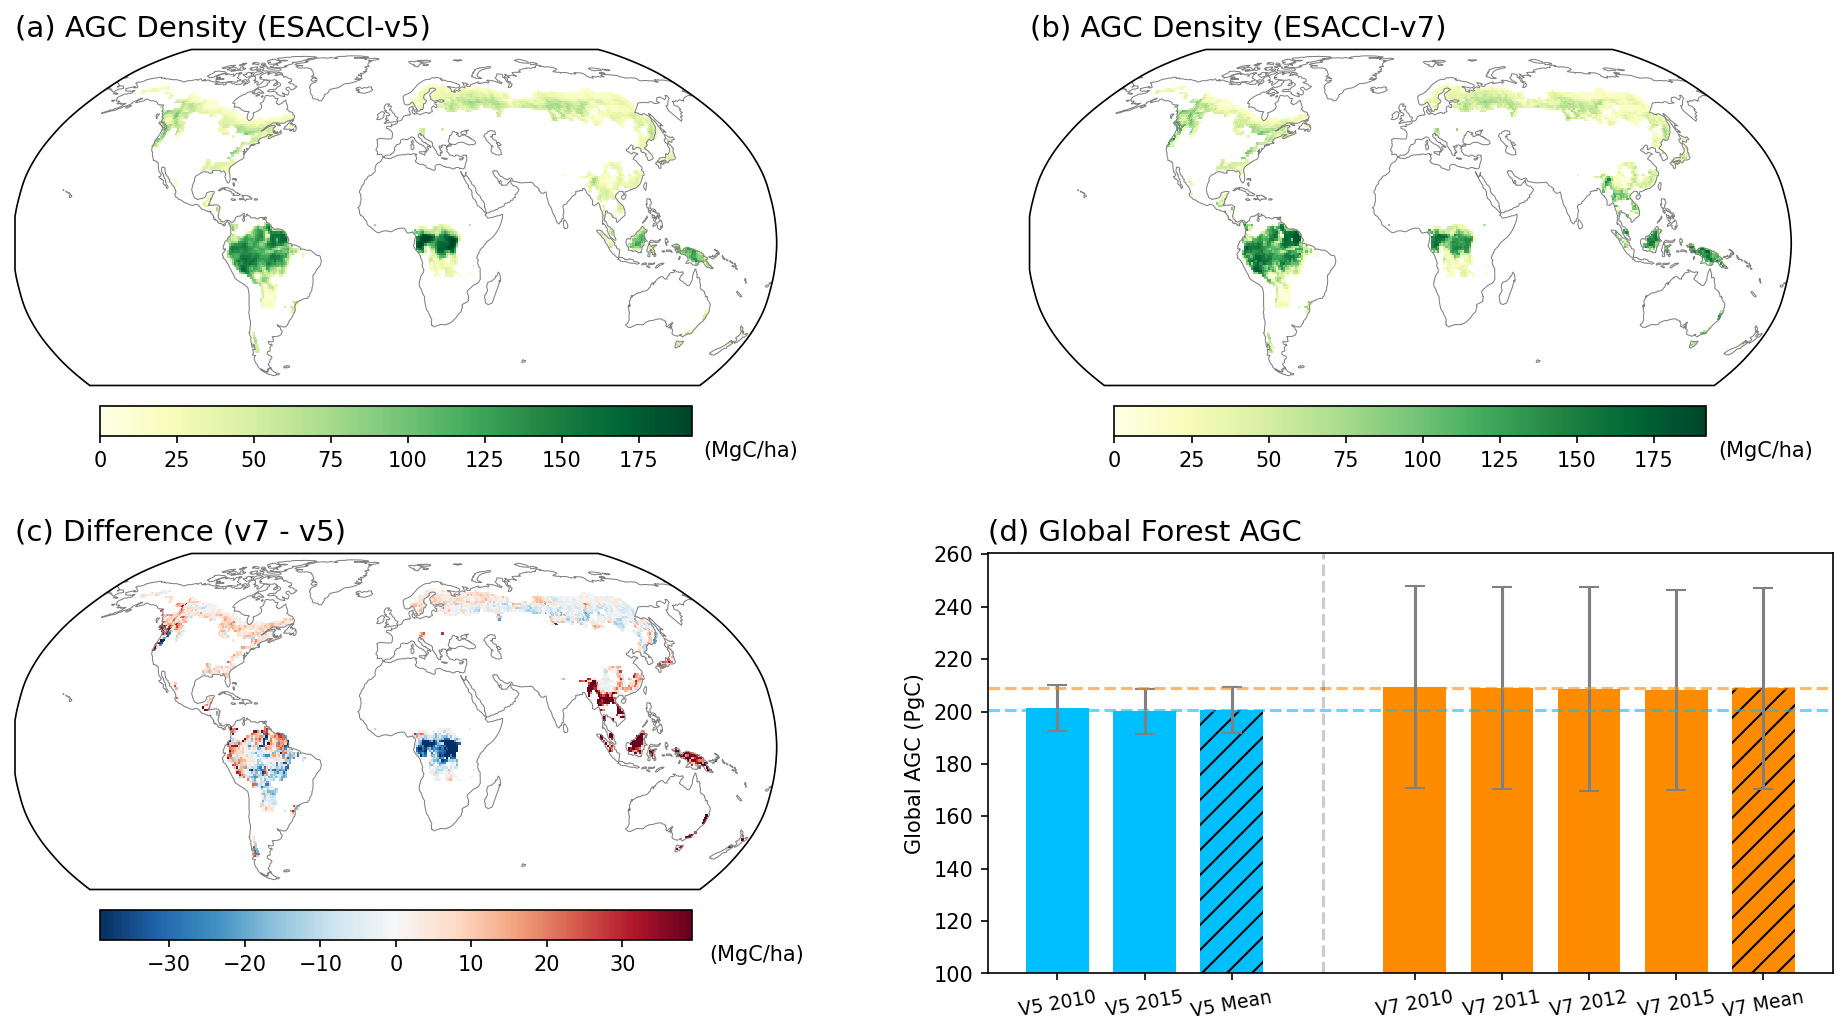

In [42]:
### ----- Difference Pattern ----- ###
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(16, 8), dpi=150)
gs = GridSpec(2, 2, fig)

ESAv5t, ESAv7t = v5_series["Mean"][0], v7_series["Mean"][0]
ESAv5t[~TreeMask] = np.nan
ESAv7t[~TreeMask] = np.nan

### 1. CCI Ver.5
vmax = np.nanpercentile([ESAv5t, ESAv7t], 99) + 20
ax1 = fig.add_subplot(gs[0, 0], projection=ccrs.Robinson())
img = ax1.pcolormesh(lon, lat[30:], ESAv5t[30:], vmin=0, vmax=vmax, cmap="YlGn",
                     transform=ccrs.PlateCarree(), shading="flat")
ax1.coastlines(color="gray", linewidth=0.5)
ax1.set_title("(a) AGC Density (ESACCI-v5)", fontsize=14, loc="left")
cbar = fig.colorbar(img, ax=ax1, orientation="horizontal", shrink=0.7, pad=0.05)
cbar.ax.text(1.02, -0.7, s="(MgC/ha)", transform=cbar.ax.transAxes)

### 2. CCI Ver.7
ax2 = fig.add_subplot(gs[0, 1], projection=ccrs.Robinson())
img = ax2.pcolormesh(lon, lat[30:], ESAv7t[30:], vmin=0, vmax=vmax, cmap="YlGn",
                     transform=ccrs.PlateCarree(), shading="flat")
ax2.coastlines(color="gray", linewidth=0.5)
ax2.set_title("(b) AGC Density (ESACCI-v7)", fontsize=14, loc="left")
cbar = fig.colorbar(img, ax=ax2, orientation="horizontal", shrink=0.7, pad=0.05)
cbar.ax.text(1.02, -0.7, s="(MgC/ha)", transform=cbar.ax.transAxes)

### 3. Difference Pattern
diff = ESAv7t - ESAv5t
lim = np.nanpercentile(np.abs(diff), 95)
ax3 = fig.add_subplot(gs[1, 0], projection=ccrs.Robinson())
img = ax3.pcolormesh(lon, lat[30:], diff[30:], vmin=-lim, vmax=lim, cmap="RdBu_r",
                     transform=ccrs.PlateCarree(), shading="flat")
ax3.coastlines(color="gray", linewidth=0.5)
ax3.set_title("(c) Difference (v7 - v5)", fontsize=14, loc="left")
cbar = fig.colorbar(img, ax=ax3, orientation="horizontal", shrink=0.7, pad=0.05)
cbar.ax.text(1.03, -0.7, s="(MgC/ha)", transform=cbar.ax.transAxes)

### 4. Global Value
ax4 = fig.add_subplot(gs[1, 1])
for x0, label, val, err in zip(x_v5, v5_series.keys(), v5_vals, v5_errs):
    ax4.bar(x0, val, width=bar_width, color="deepskyblue", hatch="//" if label == "Mean" else None)
    ax4.errorbar(x0, val, yerr=err, fmt="none", ecolor="gray", capsize=5)
for x0, label, val, err in zip(x_v7, v7_series.keys(), v7_vals, v7_errs):
    ax4.bar(x0, val, width=bar_width, color="darkorange", hatch="//" if label == "Mean" else None)
    ax4.errorbar(x0, val, yerr=err, fmt="none", ecolor="gray", capsize=5)

v5mean, v5std = getGlobal(v5_series["Mean"][0]), getGlobal(v5_series["Mean"][1])
v7mean, v7std = getGlobal(v7_series["Mean"][0]), getGlobal(v7_series["Mean"][1])
ax4.axhline(v5mean, color="deepskyblue", linestyle="--", alpha=0.6)
ax4.axhline(v7mean, color="darkorange", linestyle="--", alpha=0.6)
ax4.axvline(len(v5_series) - 0.5 + gap/2, color="black", linestyle="--", alpha=0.2)
ax4.set_ylim(100, None)

ax4.set_xticks(
    list(x_v5) + list(x_v7),
    [f"V5 {k}" for k in v5_series.keys()] + [f"V7 {k}" for k in v7_series.keys()],
    rotation=10, fontsize=9
)
ax4.set_ylabel("Global AGC (PgC)")
ax4.set_title("(d) Global Forest AGC", fontsize=14, loc="left")

plt.show(fig)
plt.close(fig)
